In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from project_baseline import process_multiselect, extract_rating
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# note: Here I tune hyperparams n_estimators and max_depth independently. This is sufficient and a grid search 
# isn't needed because the effects of these two parameters on model performance don't interact. Would be good to
# mention this in the report.

def load_and_process_data(file_name="training_data_clean.csv", vocab_size=2000, train_frac=0.7, val_frac=0.15):
    '''
    Small helper to load and process csv data
    '''
    # Load processed data
    df = pd.read_csv(file_name)

    # Drop rows with missing data
    df.dropna(inplace=True)

    # Features (just for my own reference):
    # student_id
    # task_nl - (language) "In your own words, what kinds of tasks would you use this model for?"
    # subopt_nl - (language) "Think of one task where this model gave you a suboptimal response. What did the response look like, and why did you find it suboptimal?"
    # ver_nl - (language) "When you verify a response from this model, how do you usually go about it?" 

    # task_sc - (scale) How likely are you to use this model for academic tasks?
    # subopt_sc - (scale) "Based on your experience, how often has this model given you a response that felt suboptimal?"
    # ref_sc - (scale) How often do you expect this model to provide responses with references or supporting evidence?
    # ver_sc - (scale) How often do you verify this model's responses? 

    # task_cat - (categorical) Which types of tasks do you feel this model handles best? (Select all that apply.)
    # subopt_cat - (categorical) For which types of tasks do you feel this model tends to give suboptimal responses? (Select all that apply.)

    # Following is taken from the starter code
    # Define the tasks we want to use as features (first four, clean ones)
    target_tasks = [
        'Math computations',
        'Writing or debugging code',
        'Data processing or analysis', 
        'Explaining complex concepts simply',
    ]

    # Process multi-select columns
    best_tasks_lists = process_multiselect(df['Which types of tasks do you feel this model handles best? (Select all that apply.)'], target_tasks)
    suboptimal_tasks_lists = process_multiselect(df['For which types of tasks do you feel this model tends to give suboptimal responses? (Select all that apply.)'], target_tasks)

    mlb_best = MultiLabelBinarizer()
    mlb_subopt = MultiLabelBinarizer()

    task_cat = mlb_best.fit_transform(best_tasks_lists)
    subopt_cat = mlb_subopt.fit_transform(suboptimal_tasks_lists)

    # Use some rating features
    task_sc = df['How likely are you to use this model for academic tasks?'].apply(extract_rating)
    subopt_sc = df['Based on your experience, how often has this model given you a response that felt suboptimal?'].apply(extract_rating)
    ref_sc = df['How often do you expect this model to provide responses with references or supporting evidence?'].apply(extract_rating)
    ver_sc = df["How often do you verify this model's responses?"].apply(extract_rating)

    from collections import Counter

    def pick_col(possible_names):
        for c in possible_names:
            if c in df.columns:
                return c
        raise KeyError(f"None of {possible_names} found in df.columns")

    task_nl_col = pick_col([
        "task_nl",
        "In your own words, what kinds of tasks would you use this model for?"
    ])

    subopt_nl_col = pick_col([
        "subopt_nl",
        "Think of one task where this model gave you a suboptimal response. What did the response look like, and why did you find it suboptimal?"
    ])

    ver_nl_col = pick_col([
        "ver_nl",
        "When you verify a response from this model, how do you usually go about it?"
    ])

    model_tokens = ["[this model]", "[another model]"]

    def clean_text(s: str) -> str:
        s = str(s).lower()
        for m in model_tokens:
            s = s.replace(m, " ")
        return s.strip()

    # Build corpus
    corpus_tokens = []
    for col in [task_nl_col, subopt_nl_col, ver_nl_col]:
        series_clean = df[col].fillna("").astype(str).map(clean_text)
        for txt in series_clean:
            corpus_tokens.extend(txt.split())

    counts = Counter(corpus_tokens)
    vocab = [w for w, _ in counts.most_common(vocab_size)]
    word2idx = {w: i for i, w in enumerate(vocab)}
    D_nl = len(vocab)

    # Bag of words (no avocado)

    N = len(df)
    X_nl = np.zeros((N, D_nl), dtype=np.float32)

    task_clean  = df[task_nl_col].fillna("").astype(str).map(clean_text).values
    subopt_clean = df[subopt_nl_col].fillna("").astype(str).map(clean_text).values
    ver_clean   = df[ver_nl_col].fillna("").astype(str).map(clean_text).values

    for i, (t_txt, s_txt, v_txt) in enumerate(zip(task_clean, subopt_clean, ver_clean)):
        txt = f"{t_txt} {s_txt} {v_txt}".strip()
        if not txt:
            continue
        for w in txt.split():
            j = word2idx.get(w)
            if j is not None:
                X_nl[i, j] += 1.0

    # Combine features
    X = np.hstack([task_sc.values.reshape(-1, 1), subopt_sc.values.reshape(-1, 1), 
                ref_sc.values.reshape(-1, 1), ver_sc.values.reshape(-1, 1),
                task_cat, subopt_cat])
    y = df['label'].values
    X = np.hstack([X, X_nl])

    train_size = int(train_frac * X.shape[0])
    val_size = int(val_frac * X.shape[0])

    X_train = X[:train_size, :]
    y_train = y[:train_size]
    X_val = X[train_size:train_size + val_size, :]
    y_val = y[train_size:train_size + val_size]
    X_test = X[train_size + val_size:, :]
    y_test = y[train_size + val_size:]

    return X_train, y_train, X_val, y_val, X_test, y_test

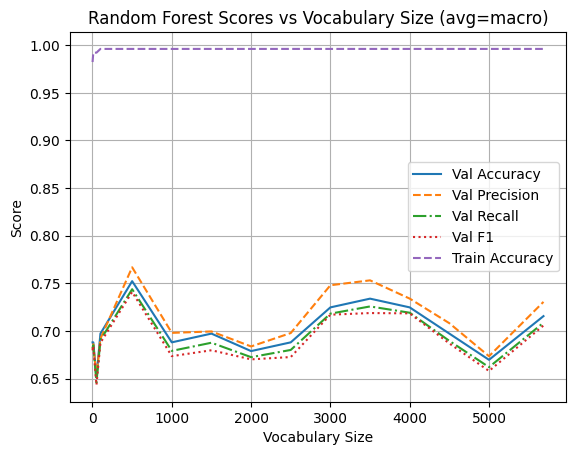

In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Tuning vocab size
vocab_sizes = [1, 10, 50, 100, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 5687]
accuracies_val = []
accuracies_train = []
precisions_val = []
recalls_val = []
f1s_val = []
precisions_train = []
recalls_train = []
f1s_train = []

avg = 'macro'

for vocab_size in vocab_sizes:
    X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(vocab_size=vocab_size)

    rf = RandomForestClassifier(
        n_estimators=201,
        max_depth=100,
        random_state=42
    )
    rf.fit(X_train, y_train)

    y_pred_val = rf.predict(X_val)
    y_pred_train = rf.predict(X_train)

    accuracies_val.append(accuracy_score(y_val, y_pred_val))
    accuracies_train.append(accuracy_score(y_train, y_pred_train))

    precisions_val.append(precision_score(y_val, y_pred_val, average=avg, zero_division=0))
    recalls_val.append(recall_score(y_val, y_pred_val, average=avg, zero_division=0))
    f1s_val.append(f1_score(y_val, y_pred_val, average=avg, zero_division=0))

    precisions_train.append(precision_score(y_train, y_pred_train, average=avg, zero_division=0))
    recalls_train.append(recall_score(y_train, y_pred_train, average=avg, zero_division=0))
    f1s_train.append(f1_score(y_train, y_pred_train, average=avg, zero_division=0))

plt.plot(vocab_sizes, accuracies_val, label='Val Accuracy')
plt.plot(vocab_sizes, precisions_val, label='Val Precision', linestyle='--')
plt.plot(vocab_sizes, recalls_val, label='Val Recall', linestyle='-.')
plt.plot(vocab_sizes, f1s_val, label='Val F1', linestyle=':')
plt.plot(vocab_sizes, accuracies_train, label='Train Accuracy', linestyle='--')
plt.xlabel('Vocabulary Size')
plt.ylabel('Score')
plt.title(f'Random Forest Scores vs Vocabulary Size (avg={avg})')
plt.legend()
plt.grid()
plt.show()

In [5]:
best_vocab_size = vocab_sizes[np.argmax(accuracies_val)]
print(best_vocab_size)
print(max(accuracies_val))

500
0.7522935779816514


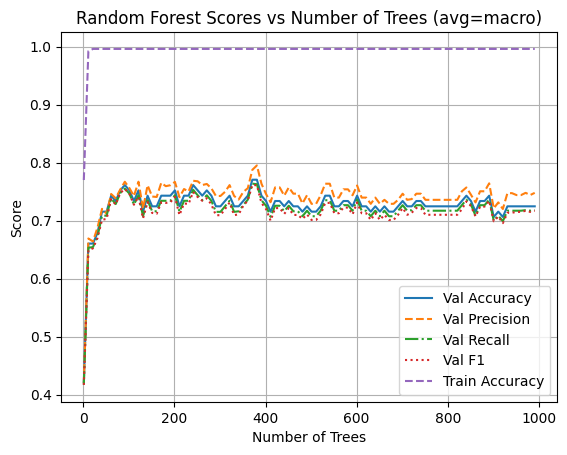

In [6]:
# Tuning n_estimators

X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(vocab_size=best_vocab_size)
accuracies_val = []
accuracies_train = []
precisions_val = []
recalls_val = []
f1s_val = []
precisions_train = []
recalls_train = []
f1s_train = []
for n in range(1, 1000, 10):
    rf = RandomForestClassifier(
    n_estimators=n,     # number of trees
    max_depth=None,      # let trees grow fully
    random_state=42
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    accuracies_val.append(accuracy_score(y_val, y_pred))
    y_pred_train = rf.predict(X_train)
    accuracies_train.append(accuracy_score(y_train, y_pred_train))

    precisions_val.append(precision_score(y_val, y_pred, average=avg, zero_division=0))
    recalls_val.append(recall_score(y_val, y_pred, average=avg, zero_division=0))
    f1s_val.append(f1_score(y_val, y_pred, average=avg, zero_division=0))

    precisions_train.append(precision_score(y_train, y_pred_train, average=avg, zero_division=0))
    recalls_train.append(recall_score(y_train, y_pred_train, average=avg, zero_division=0))
    f1s_train.append(f1_score(y_train, y_pred_train, average=avg, zero_division=0))

plt.plot(range(1, 1000, 10), accuracies_val, label='Val Accuracy')
plt.plot(range(1, 1000, 10), precisions_val, label='Val Precision', linestyle='--')
plt.plot(range(1, 1000, 10), recalls_val, label='Val Recall', linestyle='-.')
plt.plot(range(1, 1000, 10), f1s_val, label='Val F1', linestyle=':')
plt.plot(range(1, 1000, 10), accuracies_train, label='Train Accuracy', linestyle='--')
plt.xlabel('Number of Trees')
plt.ylabel('Score')
plt.title(f'Random Forest Scores vs Number of Trees (avg={avg})')
plt.legend()
plt.grid()
plt.show()

In [7]:
best_estimators = (np.argmax(accuracies_val) * 10) + 1
print(best_estimators)
print(max(accuracies_val))

371
0.7706422018348624


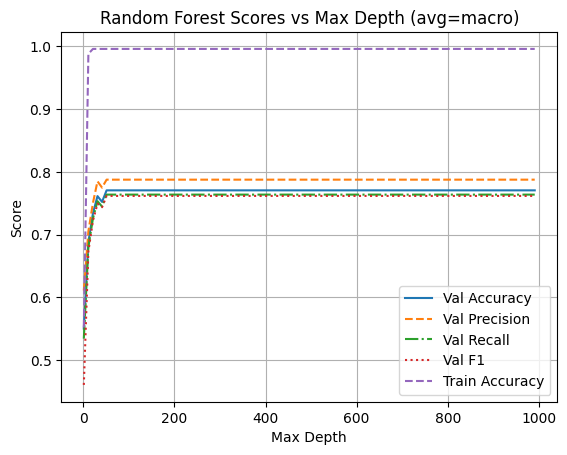

In [8]:
# Tuning max_depth

accuracies_val = []
accuracies_train = []
precisions_val = []
recalls_val = []
f1s_val = []
precisions_train = []
recalls_train = []
f1s_train = []
X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(vocab_size=best_vocab_size)
for n in range(1, 1000, 10):
    rf = RandomForestClassifier(
    n_estimators=best_estimators,     # number of trees
    max_depth=n,      # let trees grow fully
    random_state=42
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    accuracies_val.append(accuracy_score(y_val, y_pred))
    y_pred_train = rf.predict(X_train)
    accuracies_train.append(accuracy_score(y_train, y_pred_train))

    precisions_val.append(precision_score(y_val, y_pred, average=avg, zero_division=0))
    recalls_val.append(recall_score(y_val, y_pred, average=avg, zero_division=0))
    f1s_val.append(f1_score(y_val, y_pred, average=avg, zero_division=0))
    precisions_train.append(precision_score(y_train, y_pred_train, average=avg, zero_division=0))
    recalls_train.append(recall_score(y_train, y_pred_train, average=avg, zero_division=0))
    f1s_train.append(f1_score(y_train, y_pred_train, average=avg, zero_division=0))

plt.plot(range(1, 1000, 10), accuracies_val, label='Val Accuracy')
plt.plot(range(1, 1000, 10), precisions_val, label='Val Precision', linestyle='--')
plt.plot(range(1, 1000, 10), recalls_val, label='Val Recall', linestyle='-.')
plt.plot(range(1, 1000, 10), f1s_val, label='Val F1', linestyle=':')
plt.plot(range(1, 1000, 10), accuracies_train, label='Train Accuracy', linestyle='--')
plt.xlabel('Max Depth')
plt.ylabel('Score')
plt.title(f'Random Forest Scores vs Max Depth (avg={avg})')
plt.legend()
plt.grid()
plt.show()

In [9]:
best_depth = (np.argmax(accuracies_val) * 10) + 1
print(best_depth)
print(max(accuracies_val))

51
0.7706422018348624


In [10]:
# Best model

X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(vocab_size=best_vocab_size)
rf = RandomForestClassifier(
    n_estimators=best_estimators,     # number of trees
    max_depth=best_depth,      # let trees grow fully
    random_state=42
    )
# Other hyperparams actually look good with default values
rf.fit(X_train, y_train)
print("Validation accuracy:", accuracy_score(y_val, rf.predict(X_val)))
print("Training accuracy:", accuracy_score(y_train, rf.predict(X_train)))
print("Test accuracy:", accuracy_score(y_test, rf.predict(X_test)))
print("Test precision:", precision_score(y_test, rf.predict(X_test), average=avg, zero_division=0))
print("Test recall:", recall_score(y_test, rf.predict(X_test), average=avg, zero_division=0))
print("Test F1 score:", f1_score(y_test, rf.predict(X_test), average=avg, zero_division=0))

Validation accuracy: 0.7706422018348624
Training accuracy: 0.9960707269155207
Test accuracy: 0.7636363636363637
Test precision: 0.7565485775630703
Test recall: 0.7244444444444444
Test F1 score: 0.7334858014103296


In [15]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import numpy as np

# Compute predictions
y_pred = rf.predict(X_test)

# Per-class precision/recall/F1/support
precisions, recalls, f1s, supports = precision_recall_fscore_support(
    y_test, y_pred, labels=rf.classes_, zero_division=0
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)

# Per-class accuracy = diagonal / support
per_class_accuracy = cm.diagonal() / supports

# Print nicely
print("\nPer-class metrics:")
for label, p, r, f, s, acc in zip(rf.classes_, precisions, recalls, f1s, supports, per_class_accuracy):
    print(f"\n{label}:")
    print(f"  Precision: {p:.4f}")
    print(f"  Recall:    {r:.4f}")
    print(f"  F1:        {f:.4f}")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Support:   {s}")



Per-class metrics:

ChatGPT:
  Precision: 0.6438
  Recall:    0.9400
  F1:        0.7642
  Accuracy:  0.9400
  Support:   50

Claude:
  Precision: 0.5926
  Recall:    0.5333
  F1:        0.5614
  Accuracy:  0.5333
  Support:   30

Gemini:
  Precision: 0.8000
  Recall:    0.2667
  F1:        0.4000
  Accuracy:  0.2667
  Support:   30


In [12]:
from sklearn.metrics import confusion_matrix

y_pred = rf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
labels = rf.classes_   # assumes string labels like ["ChatGPT", "Claude", "Gemini"]

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()

# Tick labels
plt.xticks(np.arange(len(labels)), labels, rotation=45)
plt.yticks(np.arange(len(labels)), labels)

# Annotate each cell
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black")

plt.tight_layout()
plt.savefig("rf_confusion_matrix.png", dpi=300)
plt.close()

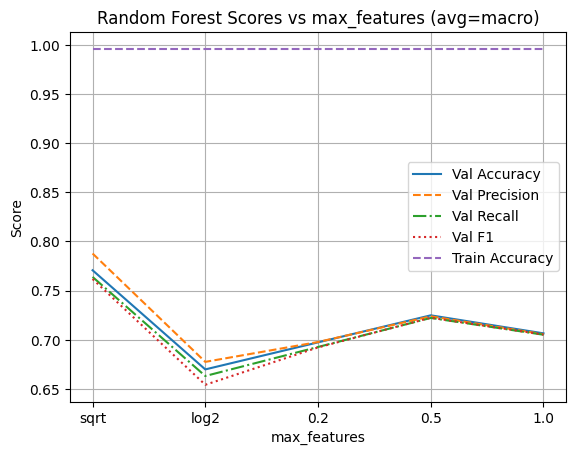

'sqrt'

In [13]:
# Tuning a few other things with boilerplate code for fun
# Tuning max_features

X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(
    vocab_size=best_vocab_size
)

max_features_grid = ['sqrt', 'log2', 0.2, 0.5, 1.0] 
accuracies_val = []
accuracies_train = []
precisions_val = []
recalls_val = []
f1s_val = []
precisions_train = []
recalls_train = []
f1s_train = []

for mf in max_features_grid:
    rf = RandomForestClassifier(
        n_estimators=best_estimators,
        max_depth=best_depth,
        max_features=mf,
        random_state=42
    )
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    accuracies_val.append(accuracy_score(y_val, y_pred))
    precisions_val.append(precision_score(y_val, y_pred, average=avg, zero_division=0))
    recalls_val.append(recall_score(y_val, y_pred, average=avg, zero_division=0))
    f1s_val.append(f1_score(y_val, y_pred, average=avg, zero_division=0))

    y_pred_train = rf.predict(X_train)
    accuracies_train.append(accuracy_score(y_train, y_pred_train))
    precisions_train.append(precision_score(y_train, y_pred_train, average=avg, zero_division=0))
    recalls_train.append(recall_score(y_train, y_pred_train, average=avg, zero_division=0))
    f1s_train.append(f1_score(y_train, y_pred_train, average=avg, zero_division=0))

xs = range(len(max_features_grid))
plt.figure()
plt.plot(xs, accuracies_val, label='Val Accuracy')
plt.plot(xs, precisions_val, label='Val Precision', linestyle='--')
plt.plot(xs, recalls_val, label='Val Recall', linestyle='-.')
plt.plot(xs, f1s_val, label='Val F1', linestyle=':')
plt.plot(xs, accuracies_train, label='Train Accuracy', linestyle='--')
plt.xticks(xs, max_features_grid)
plt.xlabel('max_features')
plt.ylabel('Score')
plt.title(f'Random Forest Scores vs max_features (avg={avg})')
plt.legend()
plt.grid()
plt.show()

best_mf_idx = int(np.argmax(accuracies_val))
best_max_features = max_features_grid[best_mf_idx]
best_max_features

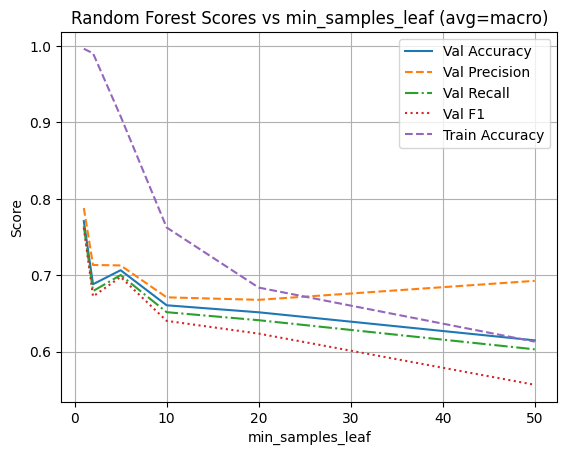

1

In [14]:
# Tuning min_samples_leaf

X_train, y_train, X_val, y_val, X_test, y_test = load_and_process_data(
    vocab_size=best_vocab_size
)

min_leaf_grid = [1, 2, 5, 10, 20, 50]
accuracies_val = []
accuracies_train = []
precisions_val = []
recalls_val = []
f1s_val = []
precisions_train = []
recalls_train = []
f1s_train = []

for leaf in min_leaf_grid:
    rf = RandomForestClassifier(
        n_estimators=best_estimators,
        max_depth=best_depth,
        max_features=best_max_features,
        min_samples_leaf=leaf,
        random_state=42
    )
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    accuracies_val.append(accuracy_score(y_val, y_pred))
    precisions_val.append(precision_score(y_val, y_pred, average=avg, zero_division=0))
    recalls_val.append(recall_score(y_val, y_pred, average=avg, zero_division=0))
    f1s_val.append(f1_score(y_val, y_pred, average=avg, zero_division=0))

    y_pred_train = rf.predict(X_train)
    accuracies_train.append(accuracy_score(y_train, y_pred_train))
    precisions_train.append(precision_score(y_train, y_pred_train, average=avg, zero_division=0))
    recalls_train.append(recall_score(y_train, y_pred_train, average=avg, zero_division=0))
    f1s_train.append(f1_score(y_train, y_pred_train, average=avg, zero_division=0))

plt.figure()
plt.plot(min_leaf_grid, accuracies_val, label='Val Accuracy')
plt.plot(min_leaf_grid, precisions_val, label='Val Precision', linestyle='--')
plt.plot(min_leaf_grid, recalls_val, label='Val Recall', linestyle='-.')
plt.plot(min_leaf_grid, f1s_val, label='Val F1', linestyle=':')
plt.plot(min_leaf_grid, accuracies_train, label='Train Accuracy', linestyle='--')
plt.xlabel('min_samples_leaf')
plt.ylabel('Score')
plt.title(f'Random Forest Scores vs min_samples_leaf (avg={avg})')
plt.legend()
plt.grid()
plt.show()

best_leaf = min_leaf_grid[int(np.argmax(accuracies_val))]
best_leaf
